# Hedging the factor exposures of the strategies

[`03_strategy_decomposition`](03_strategy_decomposition.ipynb) shows how much of the risk of each strategy comes from each factor. This notebook uses that to hedge it: each strategy is held, and the factors are sold in proportion to its exposures, so what is left is the part of the return the factors do not explain.

- **Betas of the holdings.** On the day before each monthly rebalance, every stock the portfolio is about to hold gets its betas on the seven factors from a regression of its daily returns in excess of the SELIC rate over the previous 252 trading days. The betas of the portfolio are the averages of those betas, weighted as the portfolio is. They follow the portfolio as it is when the hedge is set, rather than the past portfolios that a regression on the strategy's own returns would average.
- **What is sold.** On the rebalance date, for each real in the portfolio, the hedge sells $\beta_k$ reais of each factor $k$. The positions stay unchanged until the next rebalance, when they are closed and set again for the new holdings. The market factor is the Ibovespa in excess of the SELIC rate, which an index future delivers. The other six are long-short portfolios that cost nothing to hold, before costs. So from one rebalance to the next the hedged portfolio earns the return of the strategy minus $\sum_k \beta_k f_k$, with $f_k$ the return of factor $k$ compounded over the period.
- **Hedges.** Four versions are compared, from the simplest to the full one:
  - only the index, with the betas of a regression of each stock on the market alone;
  - the orthogonal market factor;
  - the orthogonal market and size factors;
  - all seven factors.

  With orthogonal factors, each step removes one share of the decomposition. Hedging all seven gives the same result with original or orthogonal factors.

The hedge runs from January 2012 to June 2026 for the four strategies. Quality, and so the full Combination, holds stocks from February 2011, and 2012 is the first full year with all three sleeves and a year of stock returns behind the first estimate. All returns are before transaction and borrowing costs.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, load_brazil_holdings, to_monthly,
                               BRAZIL_FACTORS, BRAZIL_STRATEGIES, DATA_START, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl
from orthofactors.decomposition import decompose
from orthofactors.plotting import set_style, factor_colors, CATEGORICAL

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

In [2]:
# The factors and the stocks from 2010, so that the betas of the first rebalances of 2012 have a past
daily = load_brazil_factors(start = DATA_START)
factors_daily = daily[BRAZIL_FACTORS]
selic_daily = daily['Risk_Free']
strategies_daily = load_brazil_strategies()
holdings, stock_returns = load_brazil_holdings(start = DATA_START)

days = factors_daily.index
# Rebalances from January 2012; the last holding period ends with the monthly sample, in June 2026
sample_end = days[days <= pd.Timestamp(MONTHLY_SAMPLE.stop) + pd.offsets.MonthEnd(0)][-1]
rebalances = sorted(d for d in holdings['Date'].unique() if pd.Timestamp('2012-01-01') <= d < sample_end)
print(f'{len(rebalances)} rebalances, from {rebalances[0]:%Y-%m-%d} to {rebalances[-1]:%Y-%m-%d}')
holdings.loc[holdings['Date'].isin(rebalances)].groupby('Strategy')['Ticker'].count().div(len(rebalances)).rename('Stocks per rebalance').round(1)

174 rebalances, from 2012-01-02 to 2026-06-01


Strategy
Combination        24.7
LowVol Momentum    10.0
Magic Formula       9.9
Quality            10.0
Name: Stocks per rebalance, dtype: float64

## Betas of the holdings

In [3]:
def stock_betas(day, tickers, window = 252, min_days = 200):
    # Betas of each stock on the seven factors, and on the market alone, from the `window` trading days up to `day`
    end = days.get_loc(day)
    F = factors_daily.iloc[max(0, end - window + 1):end + 1]
    X = np.column_stack([np.ones(len(F)), F.values])
    rows = {}
    for ticker in tickers:
        y = stock_returns[ticker].reindex(F.index).values
        ok = ~np.isnan(y)
        if ok.sum() < min_days:
            continue
        betas = np.linalg.lstsq(X[ok], y[ok], rcond = None)[0][1:]
        capm = np.linalg.lstsq(X[ok][:, :2], y[ok], rcond = None)[0][1]
        rows[ticker] = np.append(betas, capm)
    return pd.DataFrame(rows, index = BRAZIL_FACTORS + ['CAPM']).T

def portfolio_betas(window = 252, min_days = 200):
    # Betas of each strategy at each rebalance, averaged over its holdings with the portfolio weights.
    # Stocks without enough history are left out and the weights of the others rescaled.
    rows = {}
    for date in rebalances:
        signal_day = days[days.get_loc(date) - 1]
        held = holdings[holdings['Date'] == date]
        betas = stock_betas(signal_day, held['Ticker'].unique(), window, min_days)
        for strategy, group in held.groupby('Strategy'):
            weights = group.set_index('Ticker')['Weight']
            covered = weights.index.intersection(betas.index)
            rows[(strategy, date)] = pd.concat([betas.loc[covered].mul(weights[covered], axis = 0).sum() / weights[covered].sum(),
                                                pd.Series({'Coverage': weights[covered].sum()})])
    return pd.DataFrame(rows).T

betas = portfolio_betas()
betas.groupby(level = 0)['Coverage'].agg(['mean', 'min']).style.format('{:.1%}')

,mean,min
Combination,99.9%,96.7%
LowVol Momentum,100.0%,100.0%
Magic Formula,100.0%,100.0%
Quality,99.6%,90.0%


Almost every stock held has the 200 days of returns its betas need: the stocks with betas carry 99.9% of the weight of the Combination on average, and never less than 96.7%. The lowest coverage is 90.0%, for Quality, when one of its ten stocks had too little history. A stock without betas still counts in the returns of the strategy; the hedge treats its betas as the average of the other stocks.

## The hedge

In [4]:
HEDGES = ['Unhedged', 'Index only', 'Market (orthogonal)', 'Market and size (orthogonal)', 'All seven factors']

def holding_period(i):
    # Trading days on which the positions set at rebalance i are held: from the next trading day to the next rebalance
    start = days[days.get_loc(rebalances[i]) + 1]
    end = rebalances[i + 1] if i + 1 < len(rebalances) else sample_end
    return days[(days >= start) & (days <= end)]

def hedge(strategy, betas):
    # Daily excess returns of the strategy under each hedge, and the amount of each factor sold per real in the
    # portfolio. The amounts are set on each rebalance date and kept unchanged until the next one.
    pieces, amounts = [], {}
    for i, date in enumerate(rebalances):
        period = holding_period(i)
        beta = betas.loc[(strategy, date), BRAZIL_FACTORS].astype(float)

        # Orthogonal factors, estimated on the 252 days up to the day before the rebalance. Selling the orthogonal
        # factor j at its beta means selling beta_ortho[j] * S[k, j] of each original factor k.
        signal_day = days[days.get_loc(date) - 1]
        _, S, Psi = orthogonalize_swl(factors_daily.loc[:signal_day].iloc[-252:], return_matrices = True)
        beta_ortho = Psi @ beta
        sold = pd.DataFrame(0.0, index = BRAZIL_FACTORS, columns = HEDGES)
        sold.loc['Mkt_RF', 'Index only'] = betas.loc[(strategy, date), 'CAPM']
        sold['Market (orthogonal)'] = S[['Mkt_RF']] @ beta_ortho[['Mkt_RF']]
        sold['Market and size (orthogonal)'] = S[['Mkt_RF', 'SMB']] @ beta_ortho[['Mkt_RF', 'SMB']]
        sold['All seven factors'] = beta
        amounts[date] = sold

        # Value of the hedged portfolio for each real at the rebalance: the strategy, minus the gains of the factors sold
        selic = selic_daily.loc[period]
        growth = (1 + strategies_daily.loc[period, strategy] + selic).cumprod()
        factor_gains = (1 + factors_daily.loc[period]).cumprod() - 1
        value = pd.DataFrame(growth.values[:, None] - factor_gains.values @ sold.values, index = period, columns = HEDGES)
        pieces.append((value / value.shift(1).fillna(1.0) - 1).sub(selic, axis = 0))
    return pd.concat(pieces), pd.concat(amounts)

mkt_monthly = to_monthly(factors_daily[['Mkt_RF']])['Mkt_RF']

def performance(excess):
    # Monthly statistics. The hedged portfolio earns the SELIC rate plus the hedged excess return.
    monthly = to_monthly(excess.to_frame()).iloc[:, 0]
    selic = to_monthly(selic_daily.loc[excess.index].to_frame()).iloc[:, 0]
    wealth = (1 + monthly + selic).cumprod()
    return pd.Series({'Total return a year': wealth.iloc[-1] ** (12 / len(monthly)) - 1,
                      'Excess return a year': monthly.mean() * 12,
                      'Volatility': monthly.std() * np.sqrt(12),
                      'Sharpe ratio': monthly.mean() / monthly.std() * np.sqrt(12),
                      'Maximum drawdown': (wealth / wealth.cummax() - 1).min(),
                      'Correlation with Mkt_RF': monthly.corr(mkt_monthly.loc[monthly.index])})

table_format = {'Total return a year': '{:.1%}', 'Excess return a year': '{:.1%}', 'Volatility': '{:.1%}',
                'Sharpe ratio': '{:.2f}', 'Maximum drawdown': '{:.1%}', 'Correlation with Mkt_RF': '{:.2f}'}

results = {s: hedge(s, betas) for s in BRAZIL_STRATEGIES}
hedged = {s: returns for s, (returns, _) in results.items()}
combination = hedged['Combination']
selic_year = (1 + selic_daily.loc[combination.index]).prod() ** (252 / len(combination)) - 1
print(f'Combination: hedged from {combination.index[0]:%Y-%m-%d} to {combination.index[-1]:%Y-%m-%d}; '
      f'SELIC: {selic_year:.1%} a year; mean of Mkt_RF: {mkt_monthly.loc[to_monthly(combination).index].mean() * 12:.1%} a year')
combination.apply(performance).T.style.format(table_format)

Combination: hedged from 2012-01-03 to 2026-06-30; SELIC: 9.8% a year; mean of Mkt_RF: 0.6% a year


,Total return a year,Excess return a year,Volatility,Sharpe ratio,Maximum drawdown,Correlation with Mkt_RF
Unhedged,14.3%,6.0%,19.1%,0.31,-36.3%,0.85
Index only,14.6%,4.9%,9.7%,0.50,-11.2%,0.19
Market (orthogonal),12.5%,2.9%,9.1%,0.32,-11.8%,0.24
Market and size (orthogonal),11.4%,1.9%,8.6%,0.22,-11.9%,0.12
All seven factors,12.7%,3.0%,7.1%,0.42,-6.8%,0.13


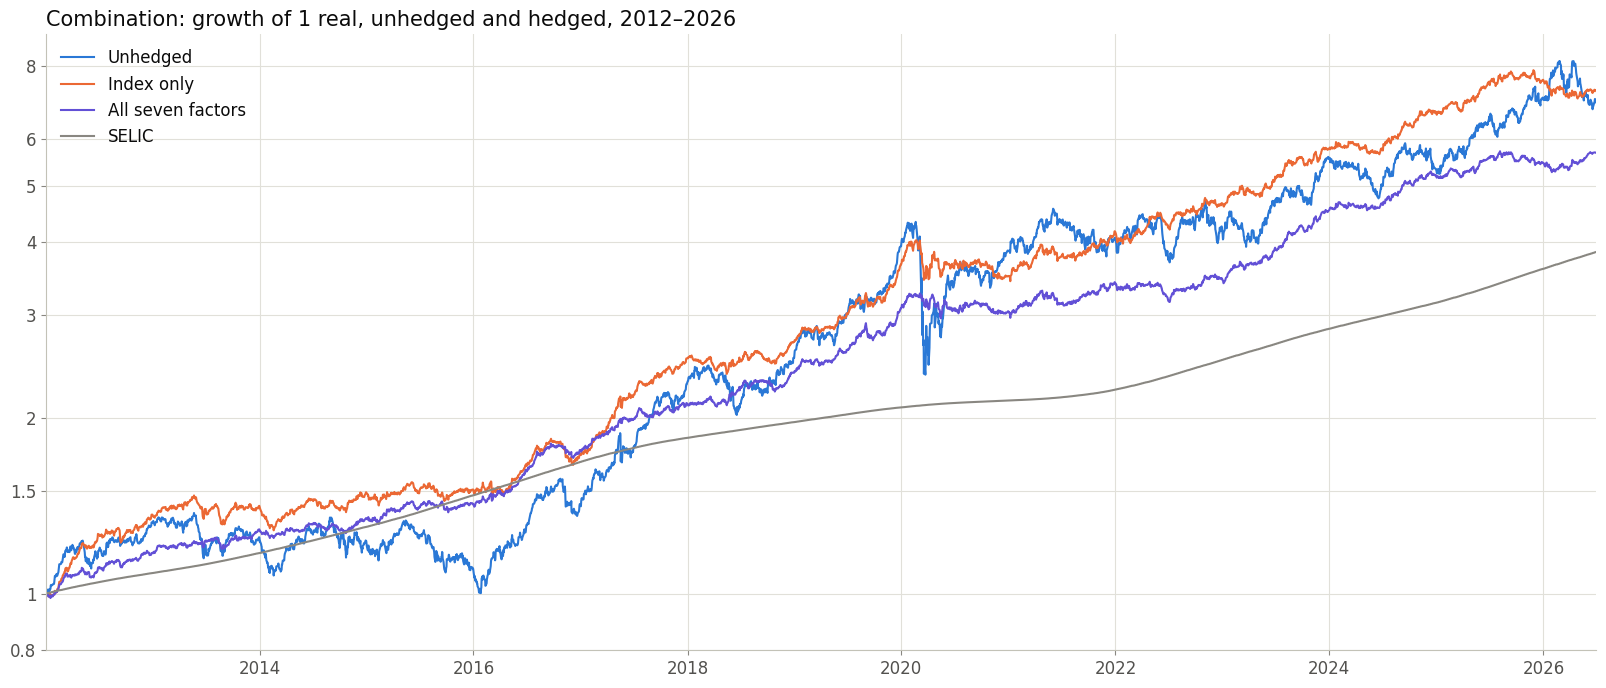

In [5]:
# Growth of 1 real, total return
total = combination[['Unhedged', 'Index only', 'All seven factors']].add(selic_daily.loc[combination.index], axis = 0)
wealth = (1 + total).cumprod()
wealth['SELIC'] = (1 + selic_daily.loc[combination.index]).cumprod()

fig, ax = plt.subplots()
for name, color in zip(wealth.columns, [CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[6], '#898781']):
    ax.plot(wealth.index, wealth[name], color = color, label = name, linewidth = 1.5)
ax.set_yscale('log')
ax.set_yticks([0.8, 1, 1.5, 2, 3, 4, 5, 6, 8])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:g}'))
ax.yaxis.set_minor_locator(ticker.NullLocator())
ax.margins(x = 0)
ax.set_title('Combination: growth of 1 real, unhedged and hedged, 2012–2026')
ax.legend(loc = 'upper left')
plt.show()

Selling only the index, 0.70 of the Ibovespa per real on average, cuts the volatility of the Combination from 19.1% to 9.7% and its maximum drawdown from −36.3% to −11.2%, and its correlation with the market falls from 0.85 to 0.19. The excess return falls from 6.0% to 4.9% a year, but with half the volatility the compound total return even rises, from 14.3% to 14.6% a year, and the Sharpe ratio goes from 0.31 to 0.50.

Hedging all seven factors leaves 12.7% a year, 2.9 points above the SELIC rate, with an excess return of 3.0% a year, a volatility of 7.1%, a maximum drawdown of −6.8% and a Sharpe ratio of 0.42. So half the excess return of the Combination is not explained by its exposures to the factors, even with betas that use only past data. That is close to the alpha of 0.27% a month, about 3.2% a year, measured with hindsight over the same years in [`03_strategy_decomposition`](03_strategy_decomposition.ipynb), which is not significant (t-statistic of 1.6).

The two orthogonal steps keep less return than the index alone for about the same volatility: 2.9% a year with the orthogonal market and 1.9% with market and size. The costs of the positions, below, show why.

## What the hedge sells

In [6]:
# Average betas of each strategy over the rebalances: how much of each factor the hedge sells per real
betas.groupby(level = 0)[['CAPM'] + BRAZIL_FACTORS].mean().loc[BRAZIL_STRATEGIES].astype(float).round(2)

,CAPM,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
Combination,0.70,0.75,0.29,0.04,0.11,-0.04,0.10,0.23
Magic Formula,0.65,0.73,0.29,-0.03,0.16,-0.02,0.14,0.22
LowVol Momentum,0.63,0.69,0.21,0.00,-0.02,-0.04,0.12,0.27
Quality,0.83,0.82,0.36,0.14,0.19,-0.06,0.05,0.21


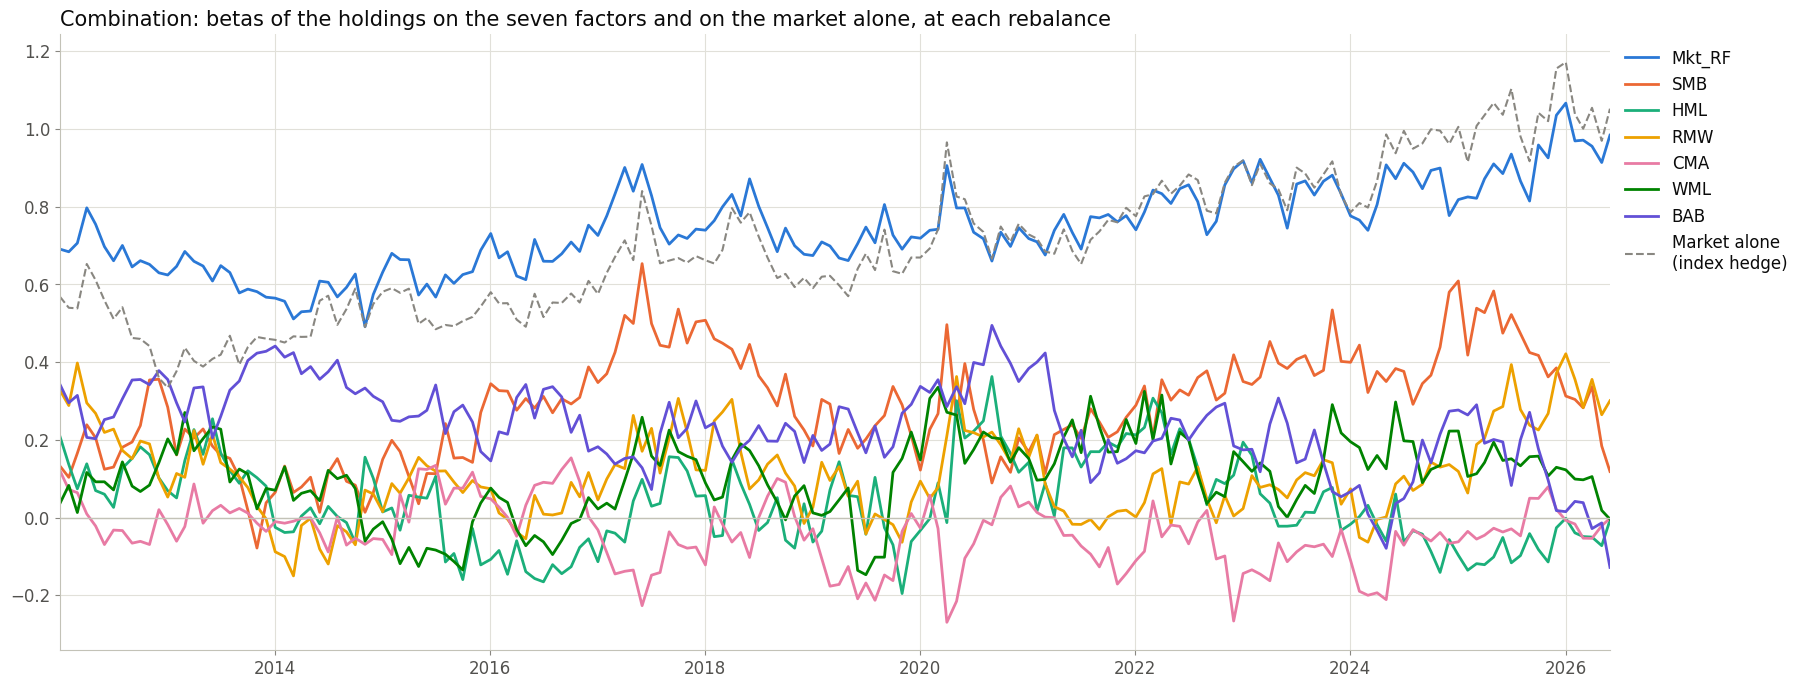

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,CAPM
min,0.49,-0.08,-0.20,-0.15,-0.27,-0.15,-0.13,0.33
mean,0.75,0.29,0.04,0.11,-0.04,0.10,0.23,0.70
max,1.07,0.65,0.36,0.42,0.15,0.34,0.49,1.17


In [7]:
combination_betas = betas.loc['Combination', BRAZIL_FACTORS + ['CAPM']].astype(float)

fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(combination_betas.index, combination_betas[factor], color = colors[factor], label = factor, linewidth = 2)
ax.plot(combination_betas.index, combination_betas['CAPM'], color = '#898781', linestyle = '--', linewidth = 1.5,
        label = 'Market alone\n(index hedge)')
ax.axhline(0, color = '#c3c2b7', linewidth = 1)
ax.margins(x = 0)
ax.set_title('Combination: betas of the holdings on the seven factors and on the market alone, at each rebalance')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

combination_betas.agg(['min', 'mean', 'max']).round(2)

In [8]:
# Market betas of the Combination measured with hindsight on its own returns over the hedged days, against the average
# of the holdings. 'Daily, with the previous day' adds the factors of the previous day and sums the two market betas.
y = combination['Unhedged']
X = factors_daily.loc[y.index]
X_both = pd.concat([X, factors_daily.shift(1).loc[y.index].add_suffix(' previous day')], axis = 1)
y_monthly = to_monthly(y.to_frame()).iloc[:, 0]

def market_beta(y, X):
    return sm.OLS(y, sm.add_constant(X)).fit().params.filter(like = 'Mkt_RF').sum()

pd.DataFrame({'Market alone': [market_beta(y, X[['Mkt_RF']]), market_beta(y, X_both[['Mkt_RF', 'Mkt_RF previous day']]),
                               market_beta(y_monthly, to_monthly(X[['Mkt_RF']])), combination_betas['CAPM'].mean()],
              'Seven factors': [market_beta(y, X), market_beta(y, X_both), market_beta(y_monthly, to_monthly(X)),
                                combination_betas['Mkt_RF'].mean()]},
             index = ['Daily returns', 'Daily, with the previous day', 'Monthly returns', 'Holdings, average']).round(2)

,Market alone,Seven factors
Daily returns,0.73,0.80
"Daily, with the previous day",0.78,0.83
Monthly returns,0.78,0.84
"Holdings, average",0.70,0.75


On average, the index hedge of the Combination sells 0.70 of the Ibovespa per real. With all seven factors it sells 0.75 of the market, 0.29 of size and 0.23 of BAB, plus smaller amounts of profitability (0.11) and momentum (0.10). The sleeves have similar betas; Quality has the largest on the market (0.82) and on size (0.36). The betas move with the holdings: the beta of the Combination on the market alone, the dashed line, goes from 0.33 to 1.17, low in 2013–2015 and close to 1 since mid-2024, and its size beta goes from −0.08 to 0.65.

These betas come from the daily returns of the previous year, and they understate the exposure to the market a little. Measured with hindsight on the Combination's own returns, its beta on the market alone is 0.73 with daily returns and 0.78 with monthly ones, against 0.70 for the holdings. Adding the market of the previous day to the daily regression brings it to 0.78 too: some of the stocks react to the market a day late, which a daily regression misses. So the index hedge sells a little too little of the market, and keeps a correlation of 0.19 with it.

## What each position cost

For the Combination, the average amount of each factor sold per real by each hedge, and what each position earned: minus the amount sold times the return of the factor until the next rebalance, averaged over the holding periods, in % a year. These returns do not compound, so they match the differences between the rows of the first table only approximately. The last row is the return of each factor over the same periods.

In [9]:
amounts = results['Combination'][1]
factor_returns = pd.DataFrame({date: (1 + factors_daily.loc[holding_period(i)]).prod() - 1
                               for i, date in enumerate(rebalances)}).T
attribution = {}
for name in HEDGES[1:]:
    sold = amounts[name].unstack()[BRAZIL_FACTORS]
    attribution[(name, 'Amount sold')] = sold.mean()
    attribution[(name, 'Return, % a year')] = -(sold * factor_returns).mean() * 1200
attribution[('Factor', 'Return, % a year')] = factor_returns.mean() * 1200
pd.DataFrame(attribution).T.round(2) + 0.0  # + 0.0 shows -0.00 as 0.00

Mkt_RF   SMB   HML   RMW   CMA  \
Index only                   Amount sold         0.70  0.00  0.00  0.00  0.00   
                             Return, % a year   -1.37  0.00  0.00  0.00  0.00   
Market (orthogonal)          Amount sold         0.81  0.07 -0.12  0.06  0.02   
                             Return, % a year   -1.22 -0.01 -0.43 -0.94 -0.06   
Market and size (orthogonal) Amount sold         0.81  0.36 -0.18  0.04  0.03   
                             Return, % a year   -1.23 -0.64 -0.02 -1.09 -0.04   
All seven factors            Amount sold         0.75  0.29  0.04  0.11 -0.04   
                             Return, % a year   -0.97 -0.44  0.64 -0.52 -0.15   
Factor                       Return, % a year    0.70 -3.59  0.52  2.20  0.12   

                                                 WML   BAB  
Index only                   Amount sold        0.00  0.00  
                             Return, % a year   0.00  0.00  
Market (orthogonal)          Amount sold        0.07 -0.01  
                             Return, % a year  -0.29 -0.41  
Market and size (orthogonal) Amount sold        0.12  0.04  
                             Return, % a year  -0.71 -0.69  
All seven factors            Amount sold        0.10  0.23  
                             Return, % a year  -1.88  0.01  
Factor                       Return, % a year  14.76  1.88

- **The index.** Selling the market lost 1.4% a year. The market earned only 0.7% a year over the SELIC rate in these periods, so selling a constant 0.70 of it would have cost 0.5%; the rest is timing. The beta of the holdings on the market alone was lowest in 2013–2015, when the market fell, and rose in 2016–2019, when it rallied. That timing is part of the return of the unhedged Combination, and the index hedge gives it up.
- **All seven factors.** The positions lost 3.3% a year in all. Momentum cost the most, 1.9%: WML earned 14.8% a year in these periods, and the hedge sold 0.10 of it per real. The market cost 1.0%, profitability 0.5% and size 0.4%, although SMB lost 3.6% a year, because the size beta was higher when small stocks did better. Selling value gained 0.6%.
- **The orthogonal market.** It is mostly the market, 0.81 per real on average, but it also holds small amounts of the other six factors, which change every month with their correlations over the previous year. Those positions lost 2.1% a year, 0.9 of it in profitability, so the orthogonal steps keep less return than the index alone. They are there to measure the risk budget below; as hedges, they do worse than the index alone.

## The decomposition as a risk budget

Hedging an orthogonal factor removes its share of the variance. The table compares the share of the monthly variance removed by each hedge, out of sample, with the decomposed $R^2$ of the same months, measured in sample as in [`03_strategy_decomposition`](03_strategy_decomposition.ipynb).

In [10]:
factors_monthly = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
budget = {}
for s, series in hedged.items():
    monthly = to_monthly(series)
    removed = 1 - monthly.var() / monthly['Unhedged'].var()
    _, dr2 = decompose(monthly['Unhedged'], factors_monthly)
    budget[s] = {('Market', 'Removed, out of sample'): removed['Market (orthogonal)'],
                 ('Market', 'Decomposed R², in sample'): dr2['Mkt_RF'],
                 ('Market and size', 'Removed, out of sample'): removed['Market and size (orthogonal)'],
                 ('Market and size', 'Decomposed R², in sample'): dr2[['Mkt_RF', 'SMB']].sum(),
                 ('All seven', 'Removed, out of sample'): removed['All seven factors'],
                 ('All seven', 'Decomposed R², in sample'): dr2.sum()}
pd.DataFrame(budget).T.style.format('{:.1%}')

The decomposition works as a risk budget out of sample. With all seven factors, the hedge removes about as much of the monthly variance as the regression explains with hindsight: 86.1% against an $R^2$ of 86.3% for the Combination, and from 4.9 points less (LowVol Momentum) to 2.2 points more (Quality) for the sleeves. The single steps differ more, by up to 9 points, because the hedge uses betas that change at every rebalance and orthogonal factors estimated on the previous year, while the decomposition fits one set of betas to the whole period. For the Combination, hedging the orthogonal market removes 77.5% of the variance, against a decomposed $R^2$ of 71.9% for the market, and adding size, 79.5% against 83.4%.

## The three sleeves

In [11]:
sleeves = pd.concat({s: hedged[s].apply(performance).T.loc[['Unhedged', 'Index only', 'All seven factors']]
                     for s in BRAZIL_STRATEGIES[1:]})
sleeves.style.format(table_format)

The sleeves tell the same story. The index hedge cuts their volatility by more than a third, to 12% to 14%, and their maximum drawdown to between −12% and −22%, with about the same total return, and it raises their Sharpe ratios: from 0.34 to 0.49 for the Magic Formula, from 0.32 to 0.41 for LowVol Momentum and from 0.21 to 0.28 for Quality. Hedging all seven factors leaves an excess return of 4.1% a year for the Magic Formula and 3.3% for LowVol Momentum, but only 1.4% for Quality, whose maximum drawdown, −31.4%, is deeper than with the index hedge alone.

## Betas of the holdings or of the strategy's own returns

The alternative is to estimate the betas from the strategy's own monthly returns over the previous 36 months, a regression of the portfolio on the factors. Those betas average the portfolios of the last three years, and they need three years of returns before the first hedge. With returns from January 2012 only, the first of these hedges is for January 2015, and the table compares the two from then on; the variance removed is measured against the unhedged strategy in the same months.

In [12]:
def hedge_from_strategy_returns(strategy, window = 36):
    # Monthly excess returns hedged with betas from the strategy's own previous `window` months
    data = pd.concat([to_monthly(strategies_daily[[strategy]]).loc[MONTHLY_SAMPLE, strategy].rename('asset'),
                      factors_monthly], axis = 1).dropna()
    y, F = data['asset'], data[BRAZIL_FACTORS]
    rows = {}
    for i in range(window, len(data)):
        beta = sm.OLS(y.iloc[i - window:i], sm.add_constant(F.iloc[i - window:i])).fit().params[BRAZIL_FACTORS]
        capm = sm.OLS(y.iloc[i - window:i], sm.add_constant(F['Mkt_RF'].iloc[i - window:i])).fit().params['Mkt_RF']
        rows[data.index[i]] = {'Unhedged': y.iloc[i], 'Index only': y.iloc[i] - capm * F['Mkt_RF'].iloc[i],
                               'All seven factors': y.iloc[i] - F.iloc[i] @ beta}
    return pd.DataFrame(rows).T

def summary(monthly, unhedged):
    return pd.Series({'Volatility': monthly.std() * np.sqrt(12), 'Sharpe ratio': monthly.mean() / monthly.std() * np.sqrt(12),
                      'Variance removed': 1 - monthly.var() / unhedged.var(),
                      'Correlation with Mkt_RF': monthly.corr(factors_monthly.loc[monthly.index, 'Mkt_RF'])})

comparison = {}
for s in BRAZIL_STRATEGIES:
    from_returns = hedge_from_strategy_returns(s)
    from_holdings = to_monthly(hedged[s])
    months = from_returns.index.intersection(from_holdings.index)
    for name in ['Index only', 'All seven factors']:
        comparison[(s, name, 'Holdings')] = summary(from_holdings.loc[months, name], from_holdings.loc[months, 'Unhedged'])
        comparison[(s, name, "Strategy's returns")] = summary(from_returns.loc[months, name], from_returns.loc[months, 'Unhedged'])
pd.DataFrame(comparison).T.style.format({'Volatility': '{:.1%}', 'Sharpe ratio': '{:.2f}', 'Variance removed': '{:.1%}',
                                         'Correlation with Mkt_RF': '{:.2f}'})

The betas of the holdings make the better full hedge. With all seven factors, they remove more of the variance than the betas of the strategy's own returns for all four strategies, 86.4% against 81.0% for the Combination, and they leave a higher Sharpe ratio for three of them, 0.46 against 0.08 for the Combination; Quality is the exception, with 0.10 against 0.11. With the index alone the two are close: the holdings remove 1.5 to 6.1 points more of the variance and the Sharpe ratios are within 0.08 of each other, but for three of the four strategies the holdings keep a higher correlation with the market, 0.17 against 0.10 for the Combination, since their daily betas understate the exposure to the market. A regression on 36 monthly returns has few observations for seven betas, and its betas average the portfolios of the last three years; the holdings give each stock 252 daily returns and follow the portfolio as it is.

## Robustness: betas from two years

The same hedges for the Combination, with the betas of each stock estimated over the previous 504 trading days instead of 252, and at least 400 days of returns.

In [13]:
betas_two_years = portfolio_betas(window = 504, min_days = 400)
hedge('Combination', betas_two_years)[0].apply(performance).T.style.format(table_format)

,Total return a year,Excess return a year,Volatility,Sharpe ratio,Maximum drawdown,Correlation with Mkt_RF
Unhedged,14.3%,6.0%,19.1%,0.31,-36.3%,0.85
Index only,14.2%,4.6%,10.4%,0.44,-14.3%,0.22
Market (orthogonal),11.9%,2.4%,9.4%,0.25,-11.7%,0.26
Market and size (orthogonal),10.7%,1.3%,9.0%,0.15,-11.6%,0.14
All seven factors,11.6%,2.1%,8.9%,0.24,-21.4%,0.19


With betas from two years of daily returns, the index hedge is about as good, with a Sharpe ratio of 0.44 against 0.50 and a maximum drawdown of −14.3% against −11.2%. The full hedge is worse: it keeps 2.1% a year of excess return, with a volatility of 8.9%, a Sharpe ratio of 0.24 and a maximum drawdown of −21.4%, against 3.0%, 7.1%, 0.42 and −6.8% with one year. So the full hedge depends on how the betas are estimated, and the index hedge much less.

These results are before costs. The index can be sold cheaply with futures, but the factor hedges mean shorting baskets of stocks, and borrowing stocks in Brazil is expensive, so the full hedge would earn less than shown here.

In [14]:
pd.concat({s: hedged[s].apply(performance).T for s in BRAZIL_STRATEGIES}).round(4).to_csv('results/hedge_performance.csv')
betas.astype(float).round(4).to_csv('results/hedge_portfolio_betas.csv')